# 第2回の練習問題
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kyorin-phys/MLIntro2026/blob/main/2/ex2.ipynb)


In [3]:
# 必要なライブラリの読み込み
!pip install -q matplotlib-fontja
import numpy as np
import matplotlib.pyplot as plt
import matplotlib_fontja
from PIL import Image

Text(0.5, 1.0, '散布図の例')

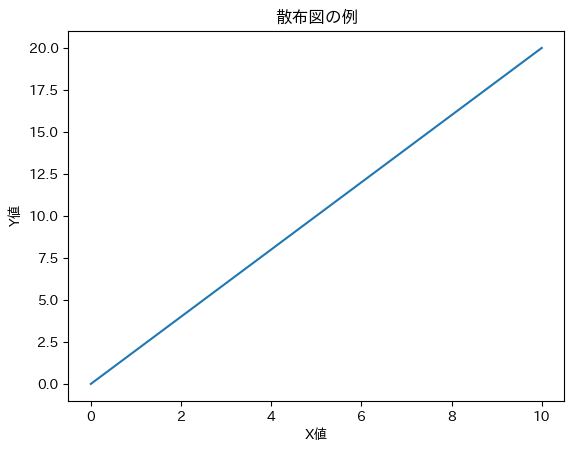

In [4]:
# matplotlib の練習問題
# 問題1: x軸を0から10まで、y軸をその2倍の値として、散布図を作成し、
# x軸ラベルを「X値」、y軸ラベルを「Y値」、タイトルを「散布図の例」
# として表示してください。

x = np.arange(0, 11)
y = x * 2

# 以下にコードを記述
plt.plot(x, y)
plt.xlabel('X値')
plt.ylabel('Y値')
plt.title('散布図の例')

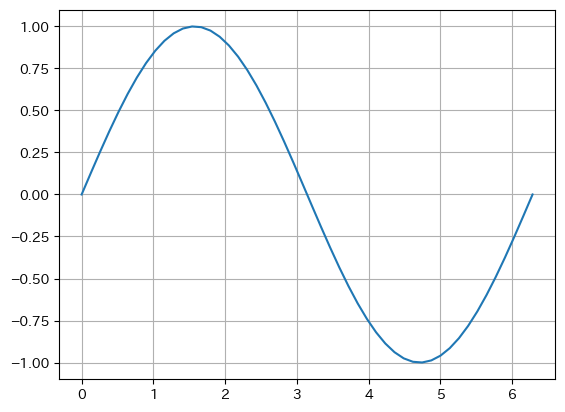

In [5]:
# 問題2: x軸を0から2πまで50等分した値、y軸をsin(x)の値として、線グラフを作成し、
# グリッドを表示してください。

x = np.linspace(0, 2 * np.pi, 50)
y = np.sin(x)

# 以下にコードを記述
plt.plot(x, y)
plt.grid(True)


In [ ]:
# numpy の練習問題
# 問題3: 1から10までの偶数のみを含むnumpy配列を作成してください。

# 以下にコードを記述
arr = np.array([i for i in range(1,11) if i % 2 == 0])
arr = np.arange(1,6) * 2
print(arr)

[ 2  4  6  8 10]


In [14]:
# 問題4: 3x3のゼロ行列を作成し、中央の要素を1に変更してください。

# 以下にコードを記述
# numpy.zeros() という関数を調べてください。
# forループやリスト内包表記で配列を作った後、numpy配列にして、reshapeで行列に変換することもできるが、
# zerosが圧倒的に簡単

A = np.zeros([3,3])
A[1][1] = 1
print(A)

[[0. 0. 0.]
 [0. 1. 0.]
 [0. 0. 0.]]


In [15]:
# 画像の表示・操作の練習問題
# 問題5: scikit-image のサンプル画像（眼底写真）を読み込み、配列の形 shape を出力して、画像を表示してください。
from skimage import data
img = data.retina()

# 以下にコードを記述
print(img.shape)

(1411, 1411, 3)


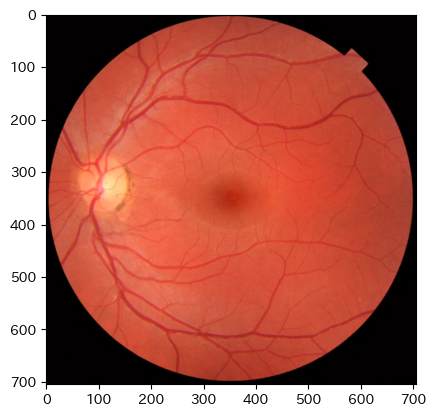

In [20]:
# 問題6: 問題5の眼底写真を、元のサイズの半分にリサイズして表示してください。
# ヒント: Image.fromarray(img) でPillowの画像に変換できる

# 以下にコードを記述
half = Image.fromarray(img)
w, h = half.size
newimg = half.resize((w//2, h//2))
plt.imshow(newimg)

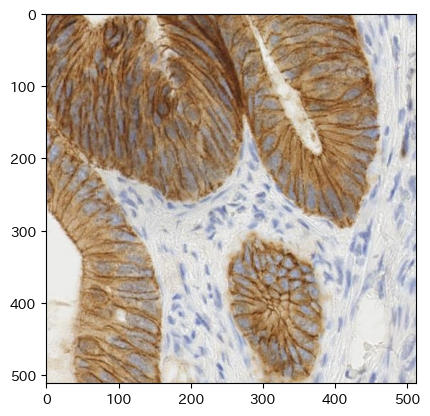

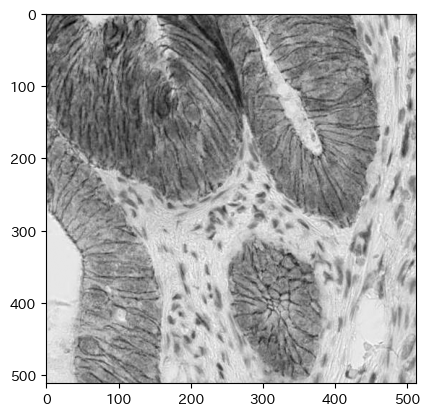

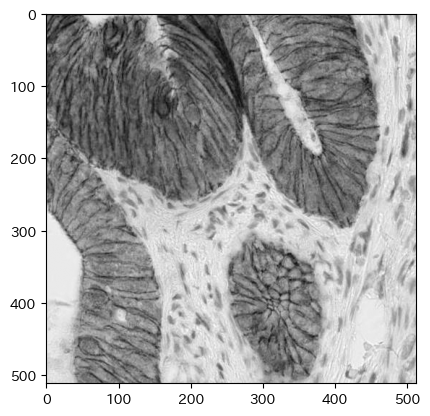

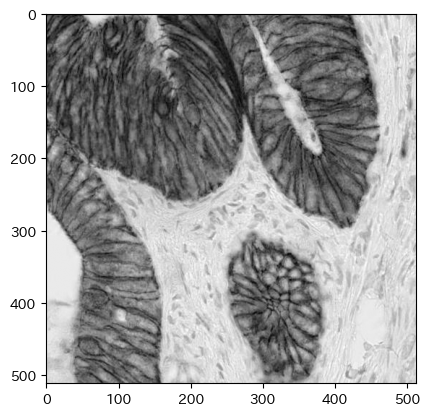

In [26]:
# 問題7: 免疫染色の画像を読み込み、R, G, B の3つのチャンネルを別々にグレースケールで並べて表示してください。
# ヒント: カラー画像の配列 ihc の形は (縦, 横, 3)。Rチャンネルは ihc[:, :, 0]
# 茶色（DAB染色）と青紫（ヘマトキシリン染色）の部分が、どのチャンネルで明るく/暗くなるか比べてみよう。
ihc = data.immunohistochemistry()
plt.imshow(ihc)
plt.show()
# 以下にコードを記述
plt.imshow(ihc[:,:,0],cmap='gray')
plt.show()
plt.imshow(ihc[:,:,1],cmap='gray')
plt.show()
plt.imshow(ihc[:,:,2],cmap='gray')

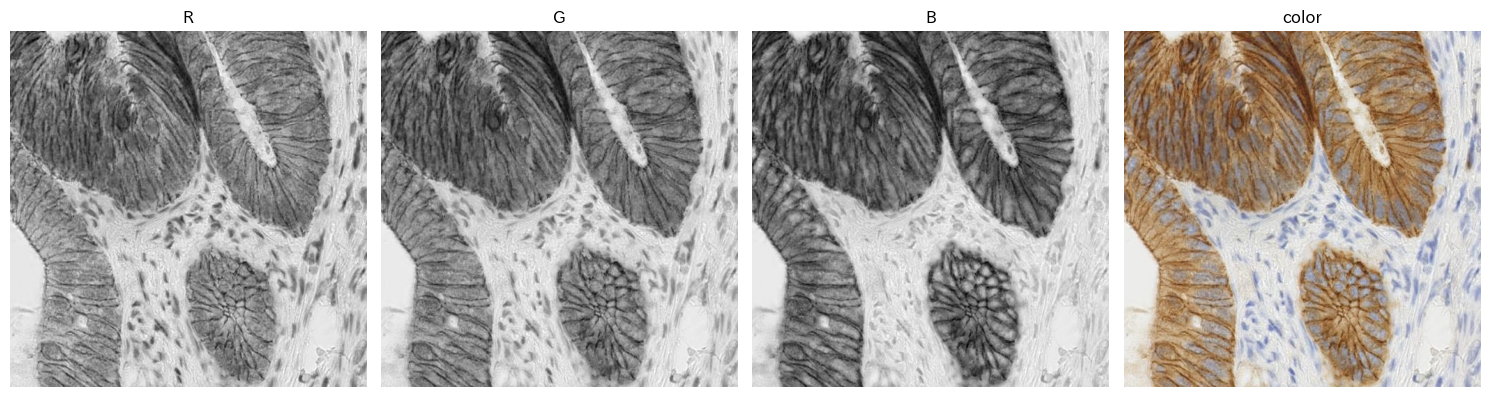

In [32]:
fig, axes = plt.subplots(1, 4, figsize=(15, 5))

for i, (ax, name) in enumerate(zip(axes, ['R', 'G', 'B'])):
    ax.imshow(ihc[:, :, i], cmap='gray')
    ax.set_title(name)
    ax.axis('off')
axes[3].imshow(ihc)
axes[3].set_title('color')
axes[3].axis('off')
plt.tight_layout()
plt.show()

## pandas と seaborn の練習問題
これまでに使用したデータ（p1.csv, p2.csv, iris.csv）とライブラリ（pandas, matplotlib, seaborn）を使います。
これらの問題を解くことで、pandas でのデータ操作と seaborn を使った可視化の理解を深めることができます。

このノートブックは2a.ipynbとは別に実行されるので、データをもう一度「ファイル」からアップロードしてから読み込む。

In [41]:
import pandas as pd
import seaborn as sns

#p1 = pd.read_csv('/content/p1.csv')
p1 = pd.read_csv('https://raw.githubusercontent.com/kyorin-phys/MLIntro2025/refs/heads/main/2/data/p1.csv')
#p2 = pd.read_csv('/content/p2.csv')
p2 = pd.read_csv('https://raw.githubusercontent.com/kyorin-phys/MLIntro2025/refs/heads/main/2/data/p2.csv')
#iris = pd.read_csv('/content/iris.csv')
iris = pd.read_csv('https://raw.githubusercontent.com/kyorin-phys/MLIntro2025/refs/heads/main/2/data/iris.csv')

In [36]:
# 問題8: p1.csv のデータ操作
# p1 データフレームの最初の3行を表示してください。
# p1 データフレームの 'S' カラムの平均値を計算して表示してください。
# p1['S'].mean() のように、カラムを取り出してから .mean() で計算できる
# 以下にコードを記述
print(p1.head(3))
print(p1['S'].mean())

      S       v
0  0.20  0.0132
1  0.26  0.0152
2  0.40  0.0181
0.81


Text(0, 0.5, '飽和度[%]')

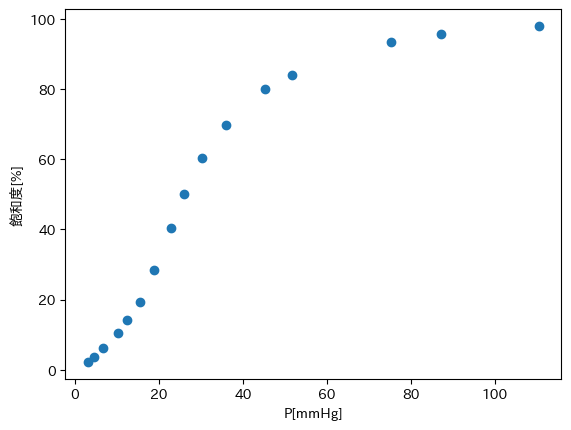

In [40]:
# 問題9: p2.csv のデータ可視化:
# p2 データフレームの 'P[mmHg]' と '飽和度[%]' の散布図を、軸ラベルとタイトル付きで作成してください。
# 以下にコードを記述

plt.scatter(p2['P[mmHg]'], p2['飽和度[%]'])
plt.xlabel('P[mmHg]')
plt.ylabel('飽和度[%]')


   SepalLength  SepalWidth  PetalLength  PetalWidth         Name
0          5.1         3.5          1.4         0.2  Iris-setosa
1          4.9         3.0          1.4         0.2  Iris-setosa
2          4.7         3.2          1.3         0.2  Iris-setosa
3          4.6         3.1          1.5         0.2  Iris-setosa
4          5.0         3.6          1.4         0.2  Iris-setosa


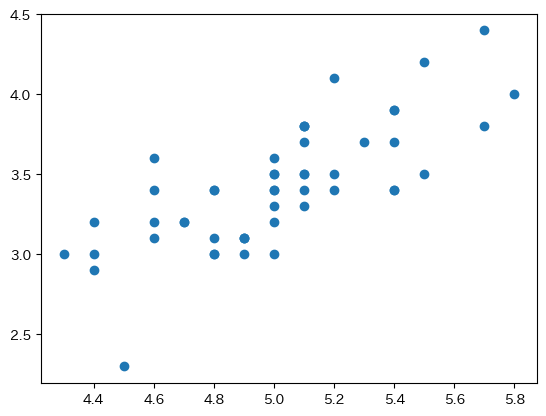

<Axes: xlabel='PetalLength', ylabel='PetalWidth'>

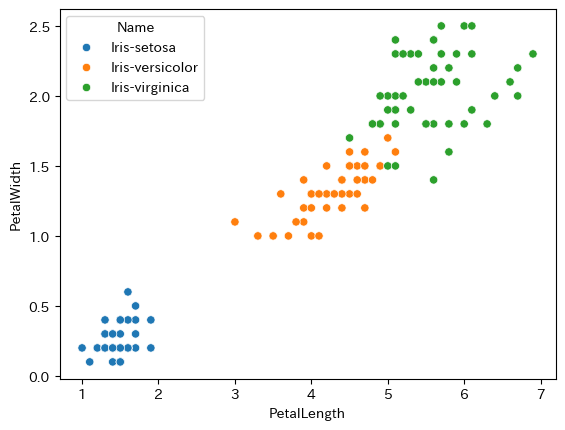

In [45]:
# 問題10:  iris.csv のデータ操作と可視化:
# iris データフレームから、'Name' が 'Iris-setosa' の行だけを抽出して新しいデータフレームを作成し、その最初の5行を表示してください。
# 抽出した setosa のデータフレームを使って、'SepalLength' と 'SepalWidth' の散布図を作成してください。
# iris データフレーム全体を使って、'PetalLength' と 'PetalWidth' の散布図を、'Name' ごとに色分けして seaborn で作成してください。
# 以下にコードを記述
setosa = iris[iris['Name'] == 'Iris-setosa']
print(setosa[:5])
plt.scatter(setosa['SepalLength'], setosa['SepalWidth'])
plt.show()
#import seaborn as sns
sns.scatterplot(data=iris, x='PetalLength', y='PetalWidth', hue='Name')